# BÁO CÁO BÀI TẬP LAB 02
## Assignment 2: Softmax Regression bằng NumPy
- **Họ và tên:** Nguyễn Văn Phát
- **MSSV:** 24521314
- **Môn học:** Học máy Thống kê (DS102)

## 1. Chuẩn bị dữ liệu

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

features = ['Age', 'Weight_kg', 'Sex', 'Num_Drugs']
target = 'Severity'

X_train = train[features].values
y_train = train[target].values
X_test = test[features].values
y_test = test[target].values

# Chuan hoa du lieu
mean = np.mean(X_train, axis=0)
std = np.std(X_train, axis=0)
X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

print("Kích thước tập train:", X_train.shape, y_train.shape)
print("Kích thước tập test:", X_test.shape, y_test.shape)
print("Số lượng từng lớp trong train:", np.bincount(y_train))

Kích thước tập train: (7920, 4) (7920,)
Kích thước tập test: (1981, 4) (1981,)
Số lượng từng lớp trong train: [4720, 2274, 926]


## 2. Cài đặt mô hình Softmax Regression

In [2]:
def one_hot(y, k):
    return np.eye(k)[y]

def softmax(z):
    e = np.exp(z - np.max(z, axis=1, keepdims=True))
    return e / np.sum(e, axis=1, keepdims=True)

class SoftmaxRegression:
    def __init__(self, lr=0.1, epochs=1000):
        self.lr = lr
        self.epochs = epochs
        self.W = None
        self.b = None
        self.losses = []

    def fit(self, X, y):
        n, d = X.shape
        k = len(np.unique(y))
        self.W = np.zeros((d, k))
        self.b = np.zeros(k)
        self.losses = []
        Y = one_hot(y, k)

        for i in range(self.epochs):
            z = np.dot(X, self.W) + self.b
            y_hat = softmax(z)

            # Tinh loss
            loss = -np.mean(np.sum(Y * np.log(y_hat + 1e-9), axis=1))
            self.losses.append(loss)

            # Gradient descent
            dz = y_hat - Y
            dW = np.dot(X.T, dz) / n
            db = np.sum(dz, axis=0) / n

            self.W -= self.lr * dW
            self.b -= self.lr * db

            if (i + 1) % 200 == 0:
                print(f"Epoch {i + 1}: Loss = {loss:.4f}")

    def predict(self, X):
        z = np.dot(X, self.W) + self.b
        return np.argmax(softmax(z), axis=1)

## 3. Huấn luyện và trực quan hóa hàm mất mát

Epoch 200: Loss = 0.8892
Epoch 400: Loss = 0.8890
Epoch 600: Loss = 0.8890
Epoch 800: Loss = 0.8890
Epoch 1000: Loss = 0.8890


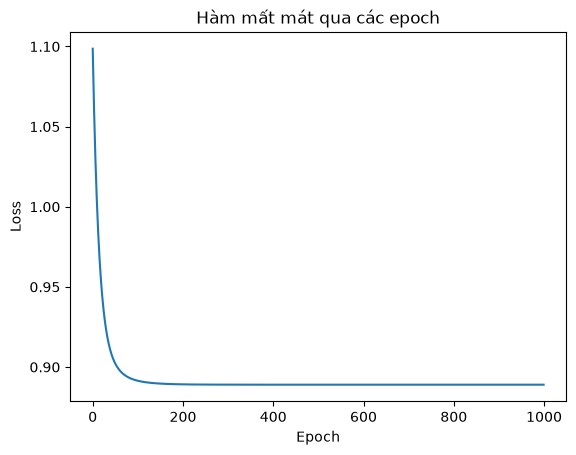

In [3]:
model = SoftmaxRegression(lr=0.1, epochs=1000)
model.fit(X_train, y_train)

# Ve bieu do loss
plt.plot(model.losses)
plt.title("Hàm mất mát qua các epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

## 4. Đánh giá mô hình trên tập test

In [4]:
y_pred = model.predict(X_test)

p_list, r_list, f1_list = [], [], []

print("--- Đánh giá theo từng lớp ---")
for c in range(3):
    tp = np.sum((y_pred == c) & (y_test == c))
    fp = np.sum((y_pred == c) & (y_test != c))
    fn = np.sum((y_pred != c) & (y_test == c))

    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f = 2 * p * r / (p + r) if (p + r) > 0 else 0.0

    p_list.append(p)
    r_list.append(r)
    f1_list.append(f)
    print(f"Lớp {c}: Precision={p:.4f}, Recall={r:.4f}, F1={f:.4f}")

print("\n--- Trung bình (Macro) ---")
print(f"Macro Precision: {np.mean(p_list):.4f}")
print(f"Macro Recall:    {np.mean(r_list):.4f}")
print(f"Macro F1-score:  {np.mean(f1_list):.4f}")

--- Đánh giá theo từng lớp ---
Lớp 0: Precision=0.6176, Recall=0.9610, F1=0.7520
Lớp 1: Precision=0.4828, Recall=0.1230, F1=0.1961
Lớp 2: Precision=0.0000, Recall=0.0000, F1=0.0000

--- Trung bình (Macro) ---
Macro Precision: 0.3668
Macro Recall:    0.3613
Macro F1-score:  0.3160
